## GenAI Fundamentals with Python

In [1]:
# Imagine Walmart wants to build a simple AI-powered assistant that can help customers and store associates with everyday store operations.

# For example, customers might ask:
# - "My grocery order is ready. Where should I collect it?"
# - "What should I do if my pickup check-in fails?"
# - "What happens if I receive a damaged product?"
# - "How can I check whether an item is available in the store?"

# Instead of manually writing every response, Walmart wants to explore how Generative AI and Python can automate these interactions while keeping responses accurate, reliable, and relevant.

# However, simply connecting Python to an AI model is not enough. We also need to understand how to control the AI's behavior, represent store information numerically, and handle situations when the AI service fails.

# The objective of this notebook is to learn these fundamentals through a fictional Walmart pickup scenario.

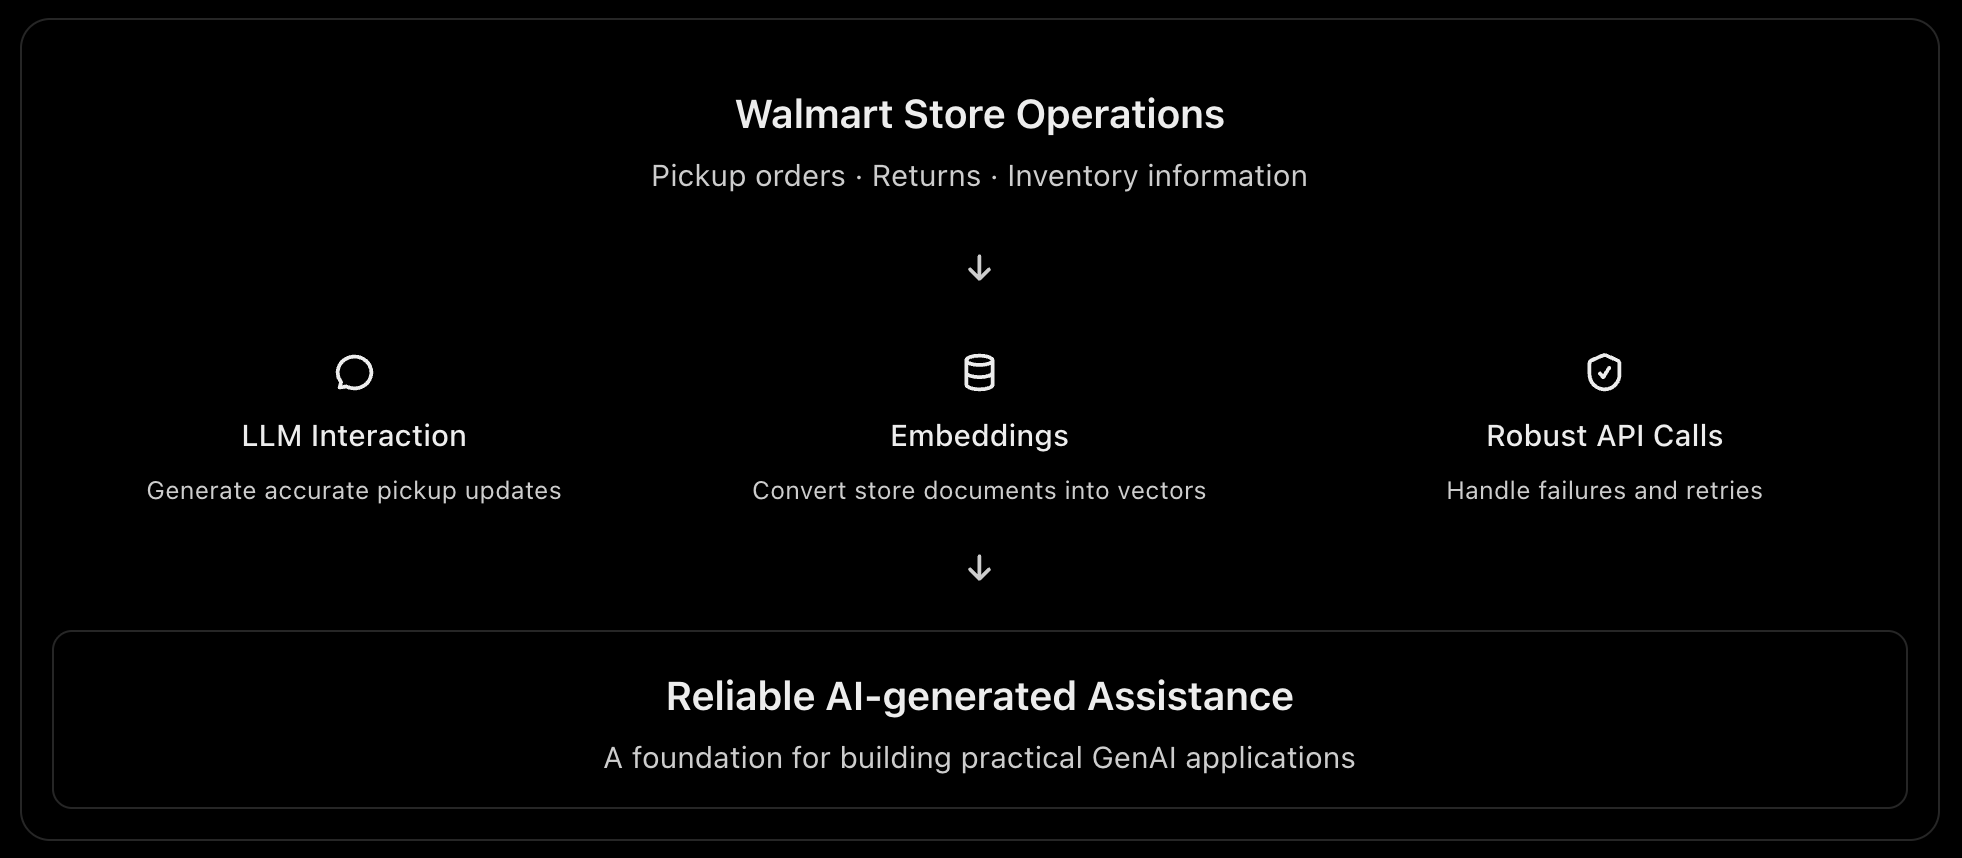

In [2]:
# Topic 1: LLM Interaction Basics

# The notebook teaches us how to send system instructions, user questions, and dynamic context to the AI model.
# It also explains how settings such as temperature, top-p, and maximum output tokens influence the generated response.

# What we learn: How Python communicates with an LLM and how to control the generated output.

In [3]:
# Topic 2: Embeddings in Practice

# How can we represent these documents in a form that an AI-powered search system could use?
# We use the OpenAI embedding model text-embedding-3-small to convert these documents into numerical vectors.

# "Customer should check in using the Walmart app"
# [0.012, -0.045, 0.087, ...]

# What we learn: How embeddings convert text into numerical vectors and prepare documents for future semantic search applications.

In [4]:
# Topic 3: Robust GenAI Calls

# What we learn: How to build more reliable AI interactions using exception handling, retries, logging, and fallback messages.

In [5]:
# LLM Interaction Basics

from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(dotenv_path=".env")

client = OpenAI(timeout=20.0, max_retries=0)

TEXT_MODEL = "gpt-4.1-mini"

# Put the three prompt inputs and the sampling settings behind one function.
def ask_model(system, question, context="", *, temperature=0.2,
              top_p=1.0, max_output_tokens=160):
    # Keep the changing facts separate from the learner's question.
    user_text = f"Task: {question}\n\nReference context:\n{context}"

    # Send the role messages and generation settings to OpenAI.
    return client.responses.create(
        model=TEXT_MODEL,
        input=[
            {"role": "system", "content": system},
            {"role": "user", "content": user_text},
        ],
        temperature=temperature,
        top_p=top_p,
        max_output_tokens=max_output_tokens,
        store=False,
    )

# Define the writing rules, the request, and the mock pickup facts.
pickup_system = "Write brief, friendly updates using only the supplied facts."
pickup_question = "Write a two-sentence Walmart pickup update."
pickup_context = "Training order WMT-104 is ready. Use pickup bay 3."

# Generate the draft and inspect its status and text.
first_reply = ask_model(pickup_system, pickup_question, pickup_context)
print("Status:", first_reply.status)
print(first_reply.output_text)

Status: completed
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay 3 when you arrive.


In [ ]:
# The grass is ________
# top_p=0.1 i.e. top 10% of 30

# green
# greener
# wet
# dry
# tall
# wavy
# .
# .
# .
# .
# 30 words it can predict

### Change the facts and try the output settings

Change the pickup bay while keeping the default settings in the wrapper. Then try a small output cap. Compare the status and text. To explore top-p separately, rerun the first call with `temperature=1.0, top_p=0.8` and compare it with `temperature=1.0, top_p=1.0`.

In [7]:
# Update the order facts and leave the wrapper's generation settings alone.
changed_context = "Training order WMT-104 is ready. Use pickup bay 5."
changed_reply = ask_model(pickup_system, pickup_question, changed_context)

# Request the same draft with a much smaller output budget.
short_reply = ask_model(
    pickup_system, pickup_question, changed_context, max_output_tokens=16,
)

# Compare each response's completion status and available text.
for label, reply in [("Bay update", changed_reply), ("Small output cap", short_reply)]:
    print(label, "| status:", reply.status)
    print(reply.output_text)

Bay update | status: completed
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay 5 when you arrive.
Small output cap | status: incomplete
Your Walmart order WMT-104 is ready for pickup. Please use pickup bay


**Takeaway** · The revised facts should lead to bay 5. If the capped reply has status `incomplete`, it may contain only part of the draft. Sampling changes can be subtle in a short, fact-based reply.

In [10]:
import openai

# Print openai version
print(openai.__version__)

import os
openai.api_key = os.getenv("OPENAI_API_KEY")

2.37.0


In [21]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4.1-mini", # https://platform.openai.com/docs/pricing
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "Write a poem on my dog named Tuffy!"}],
                  temperature=0.2, # 0-2, 0 - more deterministic, 2 - more creative
                  max_tokens=256,
                  top_p=0.6
                  )
# https://developers.openai.com/api/reference/resources/chat/subresources/completions/methods/create

# print(completion)
print(completion.choices[0].message.content)

Tuffy, my friend with fur so bright,  
A loyal heart, a joyful light.  
With wagging tail and playful cheer,  
You bring me comfort, always near.  

Through sunny days and stormy weather,  
We face the world, just us together.  
Your gentle eyes, your loving way,  
Make every moment a brighter day.  

Tuffy, my dog, so brave and true,  
Life’s better always spent with you.  
In every bark and every cuddle,  
You turn my days from gray to subtle.  

Forever friend, my furry guide,  
With you, my heart is open wide.  
Tuffy, my dog, my joy, my pride,  
Together always, side by side.


In [22]:
# Embeddings in Practice

# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="Oracle"
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[-0.01654052734375, -0.004581451416015625, 0.057403564453125, 0.04736328125, 0.0236358642578125, 0.0076751708984375, 0.0035648345947265625, -0.02325439453125, -0.02850341796875, -0.0212860107421875, -0.0034637451171875, -0.0225067138671875, 0.0211334228515625, -0.00429534912109375, 0.054443359375, 0.036590576171875, 0.0003070831298828125, 0.0089111328125, -0.01236724853515625, 0.01479339599609375, 0.052215576171875, 0.0200958251953125, -0.0163421630859375, -0.0439453125, 0.0224151611328125, 0.0195770263671875, -0.050506591796875, 0.029632568359375, 0.0235595703125, -0.057220458984375, 0.00658416748046875, -0.034942626953125, 0.04473876953125, -0.027130126953125, 0.01557159423828125, -0.01407623291015625, 0.097900390625, -0.006877899169921875, -0.0311126708984375, 0.0103912353515625, 0.031707763671875, -0.019073486328125, 0.03741455078125, 0.039947509765625, 0.0452880859375, 0.0380859375, 0.0114288330078125, -0.070556640625, 0.0227203369140625, -0.03216552734375, -0.01561737060546875, 0

In [23]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-large",
    input="Oracle"
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[-0.0300750732421875, -0.006038665771484375, -0.0276641845703125, 0.0279541015625, -0.0110626220703125, 0.0289306640625, -0.0043792724609375, 0.0218505859375, 0.0006213188171386719, 0.030426025390625, 0.037567138671875, 0.00472259521484375, -0.0045013427734375, -0.054443359375, -0.007129669189453125, 0.031341552734375, -0.025421142578125, -0.004711151123046875, -0.032623291015625, -0.024658203125, 0.0245361328125, -0.01177978515625, 0.0233612060546875, -0.0159912109375, 0.0191497802734375, 0.007564544677734375, -0.03485107421875, 0.0233306884765625, -0.01031494140625, -0.005916595458984375, 0.047576904296875, 0.046417236328125, 0.004276275634765625, 0.052276611328125, -0.05419921875, 0.009521484375, -0.0125274658203125, -0.052978515625, 0.01207733154296875, -0.0276031494140625, 0.01540374755859375, 0.00931549072265625, -0.0239410400390625, 0.0426025390625, 0.0265960693359375, -0.006336212158203125, 0.0119781494140625, 0.0180206298828125, -0.0032596588134765625, 0.012054443359375, 0.003

In [ ]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="Oracle is a multi-national company."
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[0.01061248779296875, -0.00588226318359375, 0.055145263671875, 0.050018310546875, 0.0447998046875, 0.02093505859375, 0.01218414306640625, 0.035400390625, -0.046539306640625, -0.05108642578125, -0.0008263587951660156, -0.02069091796875, -0.00864410400390625, -0.0012922286987304688, 0.01849365234375, 0.022369384765625, 0.0024776458740234375, 0.018035888671875, -0.038238525390625, -0.053619384765625, 0.053131103515625, 0.017578125, 0.0024204254150390625, -0.032684326171875, 0.044036865234375, -0.03533935546875, -0.052947998046875, 0.03607177734375, 0.053314208984375, -0.0199737548828125, 0.06182861328125, -0.0300445556640625, 0.032012939453125, -0.007793426513671875, -0.024078369140625, 0.01549530029296875, 0.055633544921875, 0.053314208984375, 0.0190277099609375, -0.013671875, -0.01480865478515625, -0.0531005859375, 0.02679443359375, 0.033111572265625, 0.020782470703125, 0.01418304443359375, -0.03082275390625, -0.027679443359375, 0.0560302734375, -0.053680419921875, -0.04254150390625, 0.

In [25]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="Oracle is a multi-national company. I work at Oracle and I use OCI vividly."
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[-0.0025539398193359375, 0.007030487060546875, 0.0323486328125, 0.044189453125, 0.0560302734375, 0.010406494140625, 0.017364501953125, 0.0196075439453125, -0.024200439453125, -0.0523681640625, 0.006702423095703125, -0.0013589859008789062, 0.007030487060546875, 0.0075531005859375, 0.0128631591796875, 0.036407470703125, 0.01343536376953125, 0.00234222412109375, -0.046783447265625, -0.042877197265625, 0.04486083984375, -0.0013608932495117188, -0.01393890380859375, 0.0019397735595703125, 0.00823974609375, -0.037811279296875, -0.06549072265625, 0.0396728515625, 0.048187255859375, -0.032196044921875, 0.0390625, -0.0433349609375, 0.0138397216796875, -0.035888671875, -0.0005698204040527344, -0.01134490966796875, 0.03546142578125, 0.03216552734375, 0.029754638671875, 0.0090484619140625, -0.01464080810546875, -0.029937744140625, 0.03546142578125, 0.007015228271484375, 0.01513671875, 0.01392364501953125, 0.005794525146484375, 0.0016565322875976562, 0.045623779296875, -0.042724609375, -0.050689697

In [26]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="cat"
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[0.025543212890625, -0.0233917236328125, -0.0160980224609375, 0.039459228515625, 0.0209808349609375, -0.026336669921875, 0.0018558502197265625, 0.0306243896484375, -0.0159454345703125, 0.005275726318359375, 0.0221405029296875, -0.0002040863037109375, 0.01041412353515625, 0.00313568115234375, 0.0299224853515625, 0.0062713623046875, -0.021453857421875, -0.0107269287109375, -0.030548095703125, 0.05755615234375, 0.034149169921875, 0.04583740234375, 0.0204620361328125, -0.046630859375, -0.00685882568359375, 0.037994384765625, -0.009246826171875, 0.0440673828125, 0.051849365234375, -0.0135040283203125, 0.0033969879150390625, -0.043121337890625, -0.01129150390625, -0.029083251953125, -0.0229644775390625, 0.01776123046875, 0.0175628662109375, -0.02801513671875, -0.0157318115234375, 0.01381683349609375, -0.03729248046875, -0.00878143310546875, 0.04583740234375, 0.011444091796875, 0.00942230224609375, -0.053314208984375, -0.022674560546875, -0.019622802734375, 0.01934814453125, 0.037200927734375

In [27]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="kitten"
)

print(response.data[0].embedding)
# Print the length of the embedding vector
print(len(response.data[0].embedding))

[-0.006473541259765625, -0.052520751953125, -0.016143798828125, -0.013458251953125, 0.01910400390625, -0.01849365234375, -0.006870269775390625, 0.044921875, -0.029052734375, 0.0032100677490234375, 0.033538818359375, -0.00949859619140625, -0.0031890869140625, 0.01215362548828125, 0.025848388671875, -0.0137939453125, -0.02783203125, -0.007694244384765625, -0.030120849609375, 0.053558349609375, 0.03729248046875, -0.054351806640625, 0.02764892578125, -0.0306243896484375, 6.657838821411133e-05, 0.0293121337890625, -0.02349853515625, -0.04583740234375, 0.0177154541015625, -0.017181396484375, 0.021636962890625, -0.045684814453125, 0.00226593017578125, -0.026123046875, -0.054229736328125, 0.0161285400390625, -0.01416015625, -0.007755279541015625, -0.020965576171875, -0.0184326171875, -0.035888671875, -0.0755615234375, 0.0285797119140625, -0.006931304931640625, 0.053619384765625, -0.04156494140625, -0.08306884765625, 0.01434326171875, 0.04388427734375, 0.06182861328125, 0.0269317626953125, 0.01

In [28]:
# Cosine Similarity
# It is used to measure the similarity between two non-zero vectors.
# It will always give results between -1 and 1.

# cool ~ cool ==> +1
# cool ~ hot ==> -1
# shoes ~ spectacles ==> 0

In [29]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="cat"
)

cat_embedding = response.data[0].embedding
print(cat_embedding)
# Print the length of the embedding vector
print(len(cat_embedding))

[0.025543212890625, -0.0233917236328125, -0.0160980224609375, 0.039459228515625, 0.0209808349609375, -0.026336669921875, 0.0018558502197265625, 0.0306243896484375, -0.0159454345703125, 0.005275726318359375, 0.0221405029296875, -0.0002040863037109375, 0.01041412353515625, 0.00313568115234375, 0.0299224853515625, 0.0062713623046875, -0.021453857421875, -0.0107269287109375, -0.030548095703125, 0.05755615234375, 0.034149169921875, 0.04583740234375, 0.0204620361328125, -0.046630859375, -0.00685882568359375, 0.037994384765625, -0.009246826171875, 0.0440673828125, 0.051849365234375, -0.0135040283203125, 0.0033969879150390625, -0.043121337890625, -0.01129150390625, -0.029083251953125, -0.0229644775390625, 0.01776123046875, 0.0175628662109375, -0.02801513671875, -0.0157318115234375, 0.01381683349609375, -0.03729248046875, -0.00878143310546875, 0.04583740234375, 0.011444091796875, 0.00942230224609375, -0.053314208984375, -0.022674560546875, -0.019622802734375, 0.01934814453125, 0.037200927734375

In [30]:
# Text Embedding

from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

response = client.embeddings.create(
    model="text-embedding-3-small",
    input="kitten"
)

kitten_embedding = response.data[0].embedding
print(kitten_embedding)
# Print the length of the embedding vector
print(len(kitten_embedding))

[-0.006473541259765625, -0.052520751953125, -0.016143798828125, -0.013458251953125, 0.01910400390625, -0.01849365234375, -0.006870269775390625, 0.044921875, -0.029052734375, 0.0032100677490234375, 0.033538818359375, -0.00949859619140625, -0.0031890869140625, 0.01215362548828125, 0.025848388671875, -0.0137939453125, -0.02783203125, -0.007694244384765625, -0.030120849609375, 0.053558349609375, 0.03729248046875, -0.054351806640625, 0.02764892578125, -0.0306243896484375, 6.657838821411133e-05, 0.0293121337890625, -0.02349853515625, -0.04583740234375, 0.0177154541015625, -0.017181396484375, 0.021636962890625, -0.045684814453125, 0.00226593017578125, -0.026123046875, -0.054229736328125, 0.0161285400390625, -0.01416015625, -0.007755279541015625, -0.020965576171875, -0.0184326171875, -0.035888671875, -0.0755615234375, 0.0285797119140625, -0.006931304931640625, 0.053619384765625, -0.04156494140625, -0.08306884765625, 0.01434326171875, 0.04388427734375, 0.06182861328125, 0.0269317626953125, 0.01

In [31]:
# Lets calculate the cosine similarity between cat_embedding and kitten_embedding

from sklearn.metrics.pairwise import cosine_similarity

import numpy as np
cat_embedding_np = np.array(cat_embedding).reshape(1, -1)
kitten_embedding_np = np.array(kitten_embedding).reshape(1, -1)
# cat_embedding_np.shape
similarity = cosine_similarity(cat_embedding_np, kitten_embedding_np)
print(similarity[0][0])

0.56964306660177


In [32]:
# PCA Visualization using Plotly

# Install required libraries if not already installed
# !pip install openai numpy scikit-learn plotly

from openai import OpenAI
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
import plotly.express as px

# Initialize OpenAI client (ensure your API key is set in the environment)
client = OpenAI()

# Sentences grouped by themes
sentences = [
    # 🏀 Sports
    "I love playing football.",
    "Basketball is my favorite sport.",
    "He enjoys running every morning.",
    "They played soccer in the park.",

    # 💻 Technology
    "Artificial Intelligence is transforming technology.",
    "Machine learning models improve with data.",
    "Quantum computing is the future of computing.",
    "Cybersecurity is crucial in the digital age.",

    # 🐶 Animals
    "The dog barked loudly at night.",
    "Cats love to sleep all day.",
    "A lion is a powerful wild animal.",
    "Birds are flying in the sky.",

    # 🍔 Food
    "I enjoy eating pizza on weekends.",
    "Pasta is a popular Italian dish.",
    "She baked a delicious chocolate cake.",
    "Fresh fruits are healthy and nutritious.",

    # ✈️ Travel
    "I love traveling to new countries.",
    "The beach was sunny and relaxing.",
    "We visited the mountains last summer.",
    "Exploring new cities is exciting."
]

# Get embeddings for all sentences
response = client.embeddings.create(
    model="text-embedding-3-large",
    input=sentences
)

# Convert to numpy array
embeddings = np.array([item.embedding for item in response.data])

# Compute cosine similarity matrix
similarity_matrix = cosine_similarity(embeddings)
print("\nCosine Similarity Matrix:\n", similarity_matrix)

# PCA for dimensionality reduction (2D)
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

# Labels for grouping (for coloring)
labels = (
    ["Sports"] * 4 +
    ["Technology"] * 4 +
    ["Animals"] * 4 +
    ["Food"] * 4 +
    ["Travel"] * 4
)

# Create an interactive Plotly scatter plot
fig = px.scatter(
    x=reduced_embeddings[:, 0],
    y=reduced_embeddings[:, 1],
    color=labels,  # Color by group
    text=[f"S{i+1}" for i in range(len(sentences))],
    hover_name=[f"S{i+1}" for i in range(len(sentences))],
    hover_data={"Sentence": sentences},
    title="2D PCA Visualization of Sentence Embeddings (Clustered)"
)

fig.update_traces(marker=dict(size=14))
fig.update_layout(
    xaxis_title="Principal Component 1",
    yaxis_title="Principal Component 2",
    template="plotly_dark"
)

fig.show()

# Print mapping to reference sentences
print("\nSentence Mapping:")
for idx, s in enumerate(sentences):
    print(f"S{idx+1}: {s}")


Cosine Similarity Matrix:
 [[1.         0.43734308 0.28487816 0.34975472 0.10085218 0.05454557
  0.0768198  0.09503885 0.04314913 0.14337725 0.13689174 0.12827261
  0.31449528 0.08957651 0.07516767 0.09096785 0.31367088 0.10233816
  0.08993613 0.16676205]
 [0.43734308 1.         0.20803045 0.24321729 0.13144222 0.06360037
  0.15350808 0.11089507 0.0234253  0.11844557 0.11547186 0.15621379
  0.22834033 0.16523443 0.13210773 0.08536351 0.23409486 0.09041539
  0.10069965 0.17409948]
 [0.28487816 0.20803045 1.         0.24219282 0.06008808 0.0873802
  0.07797978 0.0683132  0.1644522  0.2046977  0.08107625 0.11354324
  0.27559852 0.08276977 0.12308455 0.16441415 0.1723295  0.17573186
  0.13066019 0.21155565]
 [0.34975472 0.24321729 0.24219282 1.         0.0239445  0.0665307
  0.02768408 0.0497669  0.17042834 0.096693   0.10792333 0.21804166
  0.15103979 0.08181347 0.19428102 0.03444428 0.08229493 0.25177867
  0.19067004 0.13583135]
 [0.10085218 0.13144222 0.06008808 0.0239445  1.         0


Sentence Mapping:
S1: I love playing football.
S2: Basketball is my favorite sport.
S3: He enjoys running every morning.
S4: They played soccer in the park.
S5: Artificial Intelligence is transforming technology.
S6: Machine learning models improve with data.
S7: Quantum computing is the future of computing.
S8: Cybersecurity is crucial in the digital age.
S9: The dog barked loudly at night.
S10: Cats love to sleep all day.
S11: A lion is a powerful wild animal.
S12: Birds are flying in the sky.
S13: I enjoy eating pizza on weekends.
S14: Pasta is a popular Italian dish.
S15: She baked a delicious chocolate cake.
S16: Fresh fruits are healthy and nutritious.
S17: I love traveling to new countries.
S18: The beach was sunny and relaxing.
S19: We visited the mountains last summer.
S20: Exploring new cities is exciting.


In [33]:
# Create a small collection of fictional store operations documents.
documents = [
    {
        "id": "PICKUP", "department": "pickup",
        "text": "For a curbside grocery order, ask the customer to check in through the app. "
                "The customer then parks in a marked pickup bay.\n\n"
                "If the app check-in fails, the customer can call the number posted on the bay sign. "
                "An associate can help confirm the arrival.",
    },
    {
        "id": "RETURNS", "department": "service",
        "text": "For a damaged pickup item, direct the customer to the service desk. "
                "Ask for the order number and a description of the damage.\n\n"
                "The service desk records the issue and explains the next step. "
                "A training associate should avoid promising a refund.",
    },
    {
        "id": "STOCK", "department": "inventory",
        "text": "For a shelf stock check, look up the product SKU in the store inventory tool. "
                "The displayed count is a snapshot.\n\n"
                "If the tool is unavailable, ask an inventory associate to check the shelf. "
                "Confirm the count before promising availability.",
    },
]

# Use one OpenAI embedding model for both documents and future search queries.
EMBEDDING_MODEL = "text-embedding-3-small"

def embed_texts(texts):
    # Send a list of texts in one request.
    result = client.embeddings.create(model=EMBEDDING_MODEL, input=texts)

    # Return vectors in the same order as the input texts.
    return [item.embedding for item in sorted(result.data, key=lambda item: item.index)]

# Pair each document with its vector and keep the pairs in a Python list.
document_vectors = embed_texts([doc["text"] for doc in documents])
document_index = [
    {**doc, "vector": vector}
    for doc, vector in zip(documents, document_vectors)
]

# Print each document, its full embedding, and the embedding length.
for doc in document_index:
    print("Document ID:", doc["id"])
    print("Text:", doc["text"])
    print("Embedding:", doc["vector"])
    print("Embedding length:", len(doc["vector"]), "numbers")
    print()

Document ID: PICKUP
Text: For a curbside grocery order, ask the customer to check in through the app. The customer then parks in a marked pickup bay.

If the app check-in fails, the customer can call the number posted on the bay sign. An associate can help confirm the arrival.
Embedding: [-0.0239410400390625, 0.0048980712890625, -0.026824951171875, 0.01543426513671875, -0.01947021484375, -0.046051025390625, -0.02471923828125, -0.00817108154296875, 0.003795623779296875, 0.0006814002990722656, 0.00012302398681640625, -0.0125732421875, 0.064453125, 0.0031909942626953125, -0.049285888671875, 0.003398895263671875, -0.0003504753112792969, 0.002681732177734375, -0.03497314453125, 0.0251007080078125, 0.027679443359375, 0.059967041015625, 0.042877197265625, -0.0146026611328125, -0.039520263671875, -0.01580810546875, -0.00988006591796875, -0.0014944076538085938, 0.015106201171875, -0.044403076171875, -0.024658203125, -0.005767822265625, 2.1457672119140625e-06, -0.0097503662109375, -0.01853942871

**Takeaway** · Vectors from the same model have the same length. The list keeps the original text and ID alongside each vector and lives in the current Python session.

In [34]:
# Robust GenAI Calls

In [ ]:
# Building a Reliable GenAI Application with Error Handling and Retries

# Our objective is to build a safer wrapper called safe_generate() that handles failures, retries temporary errors, logs information when enabled, and provides a fallback message.

# Import error classes and the retry delay when the wrapper needs them.
from openai import APIConnectionError, APITimeoutError, InternalServerError, RateLimitError
from time import sleep

# Prepare a local message for requests that cannot be completed.
FALLBACK = "I couldn't complete the request. Please try again or ask a store associate."

def safe_generate(system, question, context="", *, generate=ask_model, log_text=False):
    # Log the prompt fields only when explicitly enabled for training data.
    if log_text:
        print("Training prompt:", {"system": system, "user": question, "context": context})

    # Give temporary failures at most two attempts in total.
    for attempt in range(1, 3):
        try:
            # Call the generator and record status for this attempt.
            reply = generate(system, question, context)
            print(f"Attempt {attempt} | status={reply.status}")

            # Show raw response text only when training logging is enabled.
            if log_text:
                print("Training response:", reply.output_text)

            # Return only complete, nonempty text to the caller.
            if reply.status == "completed" and reply.output_text.strip(): # "   Hello   ".strip() -> Hello
                return reply.output_text
            return FALLBACK

        except (APIConnectionError, RateLimitError, InternalServerError) as error:
            # The SDK's timeout error is a kind of API connection error.
            print(f"Attempt {attempt} | {type(error).__name__}")

            # Stop early if the account has exhausted its quota.
            if getattr(error, "code", None) == "insufficient_quota":
                break

            # Wait briefly before the single retry.
            if attempt == 1:
                sleep(1)

    # Return a predictable response after retries are exhausted.
    return FALLBACK

def saved_training_reply(system, question, context):
    # Reuse the completed example so this test makes no API request.
    return first_reply

def simulated_timeout(system, question, context):
    # Create a local request object to simulate the SDK's timeout error.
    from httpx import Request
    raise APITimeoutError(request=Request("POST", "https://api.openai.com/v1/responses"))

# Demonstrate prompt and response logging on the fictional success path.
safe_generate(pickup_system, pickup_question, pickup_context,
              generate=saved_training_reply, log_text=True)

# Confirm that repeated timeouts produce the local fallback.
result = safe_generate(pickup_system, pickup_question, pickup_context,
                       generate=simulated_timeout)
print("Final result:", result)

Training prompt: {'system': 'Write brief, friendly updates using only the supplied facts.', 'user': 'Write a two-sentence Walmart pickup update.', 'context': 'Training order WMT-104 is ready. Use pickup bay 3.'}
Attempt 1 | status=completed
Training response: Your Walmart order WMT-104 is ready for pickup. Please use pickup bay 3 when you arrive.
Attempt 1 | APITimeoutError
Attempt 2 | APITimeoutError
Final result: I couldn't complete the request. Please try again or ask a store associate.


**Takeaway** · The timeout example should log two failed attempts and then show the fallback. Routine logs can keep status and error types. Use raw prompt and response logs only with fictional or approved redacted data.

# Happy Learning